# Recumbent fold pair: synthetic data with a known answer

A recumbent fold with a known answer, so `01b_recumbent_fold_fit` can score every
fit against the true units. Each contact has two bends, an antiform closing
east and a synform closing west below it, joined by an overturned limb.

The data are three vertical drillholes through the fold: each contact is picked
where a hole crosses it, and bedding is read at other depths, including inside
the units. Nothing is sampled round the bends. The truth has no bubble; a
smooth interpolant that cannot see where the limbs join tends to close one off
between them. A quick check with a stand-in interpolant (**Bubble check**)
shows whether it does before the real fits are run.

**The fold** (`synthetic_fold`, x east, z up, metres), built one of three ways
(`MODEL`):

- `BentFold` (default): the parallel fold below, refolded by bending the whole
  package round an upright antiform, as a stiff package buckles (layers
  stretched on the outside of the bend, shortened on the inside, no shear along
  it). The recumbent fold's axial surface is arched: a type-3 (hook)
  interference pattern.
- `ParallelFold`: no deformation history. The contacts are parallel curves of
  a reference curve of straight limbs and circular hinges, so beds keep their
  orthogonal thickness round the hinges (Ramsay class 1B, as in buckle folds
  of competent layers). The true stratigraphic coordinate is the signed
  distance from the reference curve.
- `ShearFold`: flat layers lifted by an upright anticline and then carried
  east by a horizontal shear zone, both area preserving and exactly
  invertible. The overturned limb is thinned and the fold disharmonic.

Neither the parallel nor the bent fold is built from a flow like the ones LDI
fits with.

**Outputs** in `data/synthetic/`, in the CSV format `01b_recumbent_fold_fit`
reads (`X, Y, Z, formation` and `X, Y, Z, azimuth, dip, polarity, formation`):

- `surface_points.csv`, `orientations.csv` — the sampled contacts and bedding
- `truth.npz` — the true stratigraphic coordinate and units on a 5 m grid over the box
- `settings.json` — the model, fold and sampling settings; the fitting
  notebooks rebuild the truth on their own grid from it

True units: 1 below the older contact `rock1` (oldest), 2 between the
contacts, 3 above the younger contact `rock2` (youngest).

## Setup

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
figstyle.apply()

from synthetic_fold import BentFold, Inverted, ParallelFold, ShearFold, SmoothFold

DATA_DIR = Path("./data")
OUT_DIR = DATA_DIR / "synthetic"

## The fold

`MODEL` picks how the fold is built; all give two contacts, `rock1` (older)
and `rock2` (younger), with the same three limbs and two bends. With both hinges turning 180° (the
default for the parallel and bent folds) the pair is two recumbent isoclinal folds:
all three limbs parallel before the refold. A hinge's radius must exceed the
contact distance on its concave side (here 100 m for the antiform).

- `"bent"` (default): a recumbent pair of isoclines on a smoothly curving
  reference line (`SmoothFold`), refolded by bending the whole package round a
  gentle upright antiform (`BentFold`). The line has no straight segments or
  circular arcs: each hinge turns gradually (`width`), the limbs wander a few
  degrees, and the layer thins on the middle limb and drifts slightly in
  thickness, so it looks less constructed. Bending keeps lines across the
  package straight and normal to it (no shear along the bend); the cell prints
  its one-to-one ratio. A contact that would reach past a hinge's centre of
  curvature is refused: widen that hinge or thin the layer there.
- `"parallel"` (`ParallelFold`): no deformation history. A reference curve of
  straight limbs and circular hinges is laid out directly (`path`: lines and
  turns, left turns positive) and the contacts are parallel curves `levels` m
  either side of it, so beds keep their orthogonal thickness round the hinges.
  Contacts must stay inside each hinge's radius on its concave side.
- `"shear"` (`ShearFold`): flat layers lifted by an upright anticline, then
  carried east by a horizontal shear zone, which overturns the anticline's east
  flank and thins it. A contact is overturned where g′(z) |b′(x)| > 1.

`thickness` (parallel and bent folds) lets the layer thicken and thin along the
fold: one factor per `path` step, blended smoothly between steps, scaling every
distance from the reference curve. By default the hinges are thickened by 15 %
and the middle limb attenuated to half, as in folds of an incompetent layer;
`None` keeps it constant. Scaled contacts must still fit inside each hinge.

`INVERT` turns the stratigraphy upside down for any of them: the same
contacts with the opposite way-up, so the middle limb becomes the only upright
one and the outer limbs are overturned, as for parasitic folds on the inverted
limb of a larger recumbent fold. Limbs are named by position (`"west"`,
`"middle"`, `"east"`), not way-up.

The cell prints where each contact's bends are, and the share of each limb that
is upright (the middle of each hinge for
the parallel and bent folds, where the contact turns back for the sheared one).

In [2]:
MODEL = "bent"  # "bent" (parallel fold, refolded by bending), "parallel" or "shear"
INVERT = False   # turn the stratigraphy upside down: the middle limb becomes the only upright one

if MODEL == "bent":
    # A smoothly curving reference line: hinges turn gradually (logistic steps of the
    # given width), limbs wander a few degrees, and the layer's thickness drifts.
    fold = SmoothFold(
        levels=(-100.0, 30.0),        # m, rock1 (older) and rock2 (younger) either side of the reference line
        start=(-1500.0, 480.0),       # m, where the line starts, far west, heading east
        hinges=(                      # (arc length m, turn deg, width m); left turns positive
            (1680.0, 20.0, 120.0),    # west limb ramps up
            (2240.0, -180.0, 165.0),  # antiform, closing east: isoclinal
            (2960.0, 180.0, 110.0),   # synform, closing west: isoclinal
        ),
        wander=0.0,                   # deg, gentle wandering of the limbs
        thickness=None,  # middle limb thinned
        thickness_noise=0.0,         # smooth random drift in thickness
        seed=3,
    )
    # Refold: bend the whole package round a gentle upright antiform (25° flanks, 1100 m radii).
    fold = BentFold(base=fold, bend=ParallelFold(
        levels=(0.0, 0.0),
        start=(-3000.0, 330.0),       # m, the flat datum the first fold is laid out on
        path=(("line", 2600.0), ("turn", 25.0, 1500.0), ("line", 100.0),
              ("turn", -50.0, 1100.0), ("line", 50.0), ("turn", 25.0, 1100.0), ("line", 4000.0)),
    ))
    pad = np.arange(-300.0, 1301.0, 10.0)
    PX, PZ = np.meshgrid(pad, pad, indexing="ij")
    print(f"bending one-to-one if < 1: {fold.check(PX, PZ):.2f} (over the box padded by 300 m)")
elif MODEL == "parallel":
    fold = ParallelFold(
        levels=(-100.0, 30.0),
        start=(-1500.0, 620.0),
        path=(("line", 1600.0), ("turn", 20.0, 400.0), ("line", 300.0), ("turn", -180.0, 130.0),
              ("line", 300.0), ("turn", 180.0, 130.0), ("line", 2500.0)),
        thickness=(1.0, 1.0, 1.0, 1.15, 0.5, 1.15, 1.0),
    )
else:
    fold = ShearFold(
        levels=(150.0, 350.0),  # m, restored height of rock1 (older) and rock2 (younger)
        bump_x=0.0,           # m, centre of the upright anticline
        bump_width=230.0,       # m, its Gaussian width
        bump_height=480.0,      # m, its amplitude
        shear_z=500.0,          # m, centre of the shear zone
        shear_width=150.0,      # m, its half-thickness
        shear_offset=800.0,     # m, eastward slip of everything above it
    )
inner = fold
inner_base = inner.base if MODEL == "bent" else inner
if INVERT:
    fold = Inverted(inner)
LEVELS = dict(zip(("rock1", "rock2"), sorted(fold.levels)))

if MODEL == "parallel":
    L = inner_base._step_lengths()
    t = (LEVELS["rock2"] - LEVELS["rock1"]) * inner_base.factor(np.cumsum(L) - 0.5 * L)
    print("layer thickness per path step (m):", np.round(t).astype(int).tolist())

for name, level in LEVELS.items():
    pts, s, limb, s_bends = fold.contact(level)
    bends = pts[np.searchsorted(s, s_bends)]
    extra = ""
    if MODEL == "shear":
        x0 = np.arange(-1000.0, 2000.0, 0.5)
        lv = -level if INVERT else level
        extra = f", max g'|b'| = {(-inner.dshift(lv + inner.bump(x0)) * inner.dbump(x0)).max():.2f}"
    upright = {lb: float(np.mean(fold.younging(*pts[limb == lb][::200].T)[:, 1] > 0)) for lb in ("west", "middle", "east")
               if (limb == lb).any()}
    print(f"{name}: {len(s_bends)} bends{extra}; bends at "
          + ", ".join(f"({x:.0f}, {z:.0f})" for x, z in bends)
          + "; share upright per limb " + ", ".join(f"{lb} {u:.0%}" for lb, u in upright.items()))

bending one-to-one if < 1: 0.87 (over the box padded by 300 m)
rock1: 2 bends; bends at (529, 729), (216, 133); share upright per limb west 100%, middle 25%, east 100%
rock2: 2 bends; bends at (661, 794), (334, 230); share upright per limb west 100%, middle 25%, east 100%


## Sampling

Three vertical drillholes. A smooth scalar interpolant (NF, Surfe) sees only
the limbs a hole happens to pierce, not the bends between them, so it tends to
close a bubble while the truth has none.

- **three holes** (`HOLES`), vertical, at `Y = SECTION_Y`, running the full
  height of the box;
- **contacts** at every crossing of `rock1` or `rock2` (a recumbent contact can
  be crossed more than once by one hole);
- **bedding** about every `ORI_DZ` m down each hole, on its own set of depths,
  inside the units as well as near the contacts. Each hole is staggered, and
  each reading is nudged, so the depths do not line up from hole to hole. A
  reading within `CONTACT_CLEAR` m of a contact pick on the same hole is dropped.

`NOISE_Z` adds Gaussian noise to the contact depths; 0 keeps them exact. A
`hole` column records which drillhole a row came from (the fitting notebook
ignores it). Bedding is the true younging normal, written as azimuth/dip with
azimuth 90° (the normal is (sin dip, cos dip) in x–z), so readings on overturned
limbs point down.

In [3]:
SECTION_Y = 500.0                                             # m, the y written to the CSVs
BOX = (0.0, 1000.0)                                           # m, x and z extent of the section
HOLES = (100., 400., 650., 800.)                                    # m, easting of the three vertical drillholes
ORI_DZ = 450.0                                                # m, depth between bedding readings down each hole
CONTACT_CLEAR = 25.0                                          # m, no bedding this close to a contact pick on the same hole
NOISE_Z = 0.0                                                 # m, std of noise on contact heights
SEED = 7

def vertical_crossings(pts, x):
    """Depths where the contact polyline crosses the vertical line at easting ``x``, inside the box."""
    x0, x1 = pts[:-1, 0], pts[1:, 0]
    dx = x1 - x0
    ok = np.abs(dx) > 1e-6
    t = np.full(dx.shape, np.nan)
    t[ok] = (x - x0[ok]) / dx[ok]
    hit = ok & (t > 0.0) & (t <= 1.0)
    z = pts[:-1, 1] + t * (pts[1:, 1] - pts[:-1, 1])
    z = np.sort(z[hit & (z >= BOX[0]) & (z <= BOX[1])])
    if not len(z):
        return z
    return z[np.r_[True, np.diff(z) > 2.0]]


rows, bed_rows = [], []
rng = np.random.default_rng(SEED)
for x in HOLES:
    contact_z = []
    for name, level in LEVELS.items():
        pts, _, _, _ = fold.contact(level)
        for z in vertical_crossings(pts, x):
            rows.append((x, SECTION_Y, float(z), name, x))
            contact_z.append(float(z))
    contact_z = np.asarray(contact_z, dtype=float)
    # A small per-hole shift, then a nudge on each reading, so the depths do not
    # line up. Both stay well inside one ORI_DZ step, so each hole still samples
    # the lower and upper part of the section.
    phase = float(rng.uniform(-0.15, 0.15) * ORI_DZ)
    z0 = BOX[0] + 0.5 * ORI_DZ + phase
    while z0 < BOX[1]:
        z = None
        for _ in range(12):
            trial = float(z0 + rng.uniform(-0.08, 0.08) * ORI_DZ)
            if not (BOX[0] < trial < BOX[1]):
                continue
            if len(contact_z) and np.min(np.abs(contact_z - trial)) < CONTACT_CLEAR:
                continue
            z = trial
            break
        z0 += ORI_DZ
        if z is None:
            continue
        bed_rows.append((x, z, x))

surface_points = pd.DataFrame(rows, columns=["X", "Y", "Z", "formation", "hole"])
if NOISE_Z > 0:
    surface_points["Z"] += rng.normal(0.0, NOISE_Z, len(surface_points))

bed_xz = np.array([r[:2] for r in bed_rows], dtype=float).reshape(-1, 2)
bed_n = fold.younging(bed_xz[:, 0], bed_xz[:, 1]).reshape(-1, 2)
orientations = pd.DataFrame({
    "X": bed_xz[:, 0], "Y": SECTION_Y, "Z": bed_xz[:, 1],
    "azimuth": 90.0, "dip": np.degrees(np.arctan2(bed_n[:, 0], bed_n[:, 1])) % 360.0,
    "polarity": 1, "hole": [r[2] for r in bed_rows],
})

print(surface_points.groupby(["hole", "formation"]).size().rename("contacts").to_string())
print(f"bedding: {len(orientations)} readings on their own depths, "
      f"{int((bed_n[:, 1] < 0).sum())} overturned (younging down)")
assert (surface_points.groupby("formation").size() >= 3).all(), "01 needs at least 3 points per contact"
sp_xz = surface_points[["X", "Z"]].to_numpy(float)
d = np.linalg.norm(sp_xz[:, None, :] - bed_xz[None, :, :], axis=-1)
assert d.min() >= CONTACT_CLEAR - 1e-6, "a bedding reading landed on a contact pick"

hole   formation
100.0  rock1        1
       rock2        1
400.0  rock1        3
       rock2        3
650.0  rock1        1
       rock2        3
800.0  rock1        1
       rock2        1
bedding: 8 readings on their own depths, 2 overturned (younging down)


## Truth and data

True units on the box, the true contacts with their bends (crosses), and the
three drillholes. Contact picks are filled where the beds are upright and open
where they are overturned. Bedding way-up bars sit at their own depths, off
the picks.

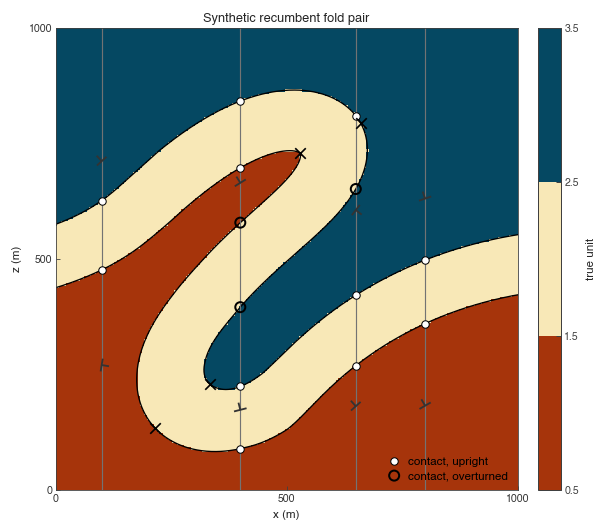

unit shares in the box: {1: 0.323, 2: 0.293, 3: 0.384}


In [4]:
GRID_STEP = 5.0  # m
x_ax = np.arange(BOX[0], BOX[1] + 0.5 * GRID_STEP, GRID_STEP)
z_ax = np.arange(BOX[0], BOX[1] + 0.5 * GRID_STEP, GRID_STEP)
XX, ZZ = np.meshgrid(x_ax, z_ax, indexing="ij")
phi_true = fold.restored_height(XX, ZZ)
unit_true = fold.units(XX, ZZ)

contacts_true = {}
cmap, norm = figstyle.litho_cmap([1, 2, 3])
fig, ax = plt.subplots(figsize=(5.5, 5.0))
m = ax.pcolormesh(x_ax, z_ax, unit_true.T, cmap=cmap, norm=norm, shading="auto", rasterized=True)
for name, level in LEVELS.items():
    pts, s, limb, s_bends = fold.contact(level)
    contacts_true[name] = pts
    ax.plot(pts[:, 0], pts[:, 1], color="k", lw=0.8)
    bends = pts[np.searchsorted(s, s_bends)]
    ax.scatter(bends[:, 0], bends[:, 1], marker="x", s=40, color="k", linewidths=1.0, zorder=4)
for x in HOLES:
    ax.plot([x, x], BOX, color="0.45", lw=0.7, zorder=2)
# Way-up of each contact pick: open markers where the beds are overturned.
over = fold.younging(surface_points["X"].to_numpy(), surface_points["Z"].to_numpy())[:, 1] < 0
ax.scatter(surface_points.loc[~over, "X"], surface_points.loc[~over, "Z"], s=20, color="white",
           edgecolors="k", linewidths=0.6, zorder=3, label="contact, upright")
ax.scatter(surface_points.loc[over, "X"], surface_points.loc[over, "Z"], s=36, facecolors="none",
           edgecolors="k", linewidths=1.2, zorder=3, label="contact, overturned")
figstyle.draw_younging(ax, bed_xz, bed_n, quiver_scale=0.03)
ax.set_xlim(*BOX)
ax.set_ylim(*BOX)
figstyle.format_section_ax(ax, title="Synthetic recumbent fold pair")
figstyle.add_colorbar(fig, m, ax, "true unit")
ax.legend(loc="lower right", frameon=False, fontsize=7)
plt.show()

print("unit shares in the box:", {int(u): round(float(np.mean(unit_true == u)), 3) for u in (1, 2, 3)})

## Bubble check

A quick stand-in for NF and Surfe, to see whether the data make a smooth
scalar interpolant close off a bubble before running the real fits. It is a
radial-basis interpolant (scipy `RBFInterpolator`, thin-plate spline, linear
trend) through the contacts at their true levels. Each bedding reading, wherever
it sits on a hole, becomes two points a step `DIPOLE` up and down its way-up,
valued at the true stratigraphic coordinate there. Bubbles are interior extrema
of the field (red triangles), found as grid cells above or below all 8
neighbours. The truth should have none.

This is only a proxy. It is given the contact levels, which NF and Surfe have
to find themselves, and its kernel is not theirs. If it shows no bubble, move a
hole so that it cuts the overturned limb before fitting; if it does, the real
fits still have to be checked in `01` and `01b`.

truth: 0 maxima, 5 minima (should be 0, 0)
smooth interpolant: 1 maxima, 1 minima -> bubble(s)


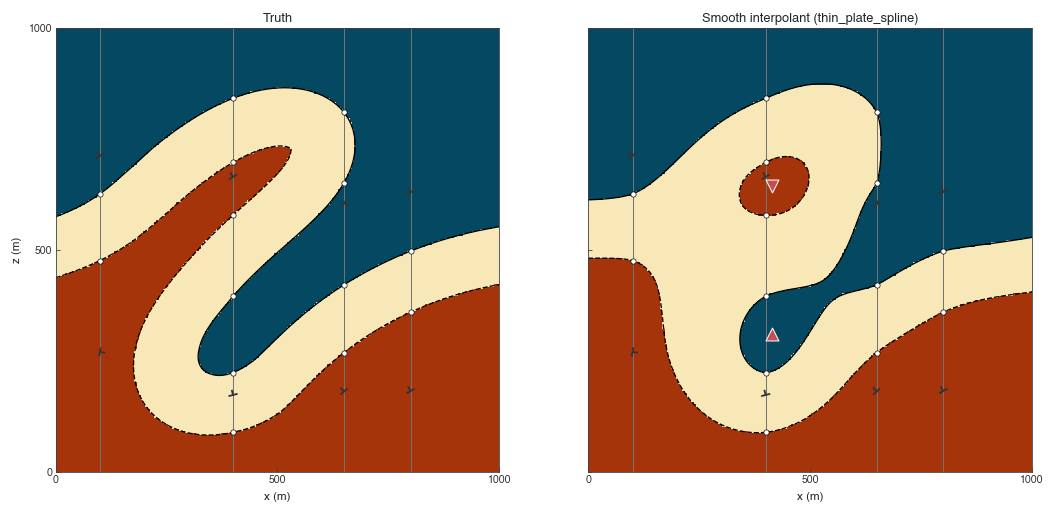

In [5]:
from scipy.interpolate import RBFInterpolator

DIPOLE = 10.0                  # m, offset of the point pair that stands in for each bedding reading
KERNEL = "thin_plate_spline"   # scipy RBF kernel; minimum curvature, like a smooth implicit model


def interior_extrema(f):
    # Grid cells strictly above (below) all 8 neighbours: interior maxima (minima).
    c = f[1:-1, 1:-1]
    nbrs = [f[1 + i:f.shape[0] - 1 + i, 1 + j:f.shape[1] - 1 + j]
            for i in (-1, 0, 1) for j in (-1, 0, 1) if (i, j) != (0, 0)]
    is_max = np.all([c > n for n in nbrs], axis=0)
    is_min = np.all([c < n for n in nbrs], axis=0)
    return np.argwhere(is_max) + 1, np.argwhere(is_min) + 1


# Contacts carry their level. Each bedding reading, at its own depth, becomes two points a
# step up and a step down its way-up, valued at the true stratigraphic coordinate there.
lv = surface_points["formation"].map(LEVELS).to_numpy(float)
phi_bed = fold.restored_height(bed_xz[:, 0], bed_xz[:, 1])
centres = np.vstack([surface_points[["X", "Z"]].to_numpy(float), bed_xz + DIPOLE * bed_n, bed_xz - DIPOLE * bed_n])
values = np.concatenate([lv, phi_bed + DIPOLE, phi_bed - DIPOLE])
rbf = RBFInterpolator(centres, values, kernel=KERNEL, degree=1)
proxy = rbf(np.column_stack([XX.ravel(), ZZ.ravel()])).reshape(XX.shape)

maxima, minima = interior_extrema(proxy)
# Only the band the layers occupy matters for the truth: far from them the parallel fold's
# distance field has creases that are not geology, so clip to a margin round the contacts.
levels = sorted(LEVELS.values())
margin = 0.5 * (levels[1] - levels[0])
t_max, t_min = interior_extrema(np.clip(phi_true, levels[0] - margin, levels[1] + margin))
print(f"truth: {len(t_max)} maxima, {len(t_min)} minima (should be 0, 0)")
print(f"smooth interpolant: {len(maxima)} maxima, {len(minima)} minima -> "
      f"{'bubble(s)' if len(maxima) + len(minima) else 'no bubble'}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.0), sharey=True)
for ax, field, title in ((axes[0], phi_true, "Truth"), (axes[1], proxy, f"Smooth interpolant ({KERNEL})")):
    ax.pcolormesh(x_ax, z_ax, (np.digitize(field, levels) + 1).T, cmap=cmap, norm=norm,
                  shading="auto", rasterized=True)
    ax.contour(x_ax, z_ax, field.T, levels=levels, colors="k", linewidths=0.8)
    for x in HOLES:
        ax.plot([x, x], BOX, color="0.45", lw=0.6, zorder=2)
    ax.scatter(surface_points["X"], surface_points["Z"], s=10, color="white", edgecolors="k", linewidths=0.4, zorder=3)
    figstyle.draw_younging(ax, bed_xz, bed_n, quiver_scale=0.04)
    ax.set_xlim(*BOX)
    ax.set_ylim(*BOX)
    figstyle.format_section_ax(ax, ylabel=ax is axes[0], title=title)
for idx, marker in ((maxima, "^"), (minima, "v")):
    if len(idx):
        axes[1].scatter(x_ax[idx[:, 0]], z_ax[idx[:, 1]], marker=marker, s=60, color="#C44E52",
                        edgecolors="white", linewidths=0.6, zorder=5)
plt.show()

## Save

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
surface_points.to_csv(OUT_DIR / "surface_points.csv", index=False)
orientations.to_csv(OUT_DIR / "orientations.csv", index=False)
np.savez_compressed(
    OUT_DIR / "truth.npz",
    x=x_ax, z=z_ax, restored_height=phi_true.astype(np.float32), unit=unit_true,
    **{f"contact_{name}": pts for name, pts in contacts_true.items()},
)
settings = dict(
    model=type(inner).__name__, fold=inner.asdict(), inverted=INVERT,
    units={"1": "below rock1 (oldest)", "2": "between rock1 and rock2", "3": "above rock2 (youngest)"},
    sampling=dict(section_y=SECTION_Y, box=list(BOX), holes=list(HOLES), ori_dz=ORI_DZ,
                  contact_clear=CONTACT_CLEAR, noise_z=NOISE_Z, seed=SEED),
)
(OUT_DIR / "settings.json").write_text(json.dumps(settings, indent=2))
print("wrote", sorted(p.name for p in OUT_DIR.iterdir()), "to", OUT_DIR)

wrote ['orientations.csv', 'settings.json', 'surface_points.csv', 'truth.npz'] to data/synthetic
